In [11]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from dotenv import load_dotenv
from pymongo import MongoClient


In [4]:
RUTA_PROYECTO = Path.cwd().parent

load_dotenv(RUTA_PROYECTO / "atlas-credentials.env")

uri = os.getenv("MONGODB_URI")

if not uri:
    raise ValueError("No se encontró MONGODB_URI")

cliente = MongoClient(uri)

db = cliente["monitoreo_iot"]
coleccion = db["mediciones_dht22"]

cliente.admin.command("ping")

print("Conexión exitosa con MongoDB Atlas")

Conexión exitosa con MongoDB Atlas


In [5]:
documentos = list(
    coleccion.find({}, {"_id": 0})
)

df = pd.DataFrame(documentos)

print(f"Total de registros: {len(df)}")

df.head()

Total de registros: 83


,fila_origen,archivo_origen,estado,fase,fecha_hora_recepcion_pc,humedad_relativa_aire_pct,segundos_desde_inicio,temperatura_aire_c
0,1,verificacion_dht22_20261106_151438_945598.csv,OK,VERIFICACION_DHT22,2026-11-06 20:14:41.163,64.5,2.219,29.3
1,2,verificacion_dht22_20261106_151438_945598.csv,OK,VERIFICACION_DHT22,2026-11-06 20:14:51.193,64.7,12.249,29.3
2,3,verificacion_dht22_20261106_151438_945598.csv,OK,VERIFICACION_DHT22,2026-11-06 20:15:01.224,64.6,22.280,29.3
3,4,verificacion_dht22_20261106_151438_945598.csv,OK,VERIFICACION_DHT22,2026-11-06 20:15:11.253,64.7,32.309,29.2
4,5,verificacion_dht22_20261106_151438_945598.csv,OK,VERIFICACION_DHT22,2026-11-06 20:15:21.285,64.4,42.341,29.3


In [6]:
df["fecha_hora_recepcion_pc"] = pd.to_datetime(
    df["fecha_hora_recepcion_pc"],
    utc=True
)

# Conservar únicamente las mediciones válidas
df = df[df["estado"] == "OK"].copy()

# Eliminar registros incompletos
df = df.dropna(
    subset=[
        "fecha_hora_recepcion_pc",
        "temperatura_aire_c",
        "humedad_relativa_aire_pct"
    ]
)

# Convertir a la hora local de Perú
df["fecha_local"] = (
    df["fecha_hora_recepcion_pc"]
    .dt.tz_convert("America/Lima")
)

# Ordenar cronológicamente
df = df.sort_values(
    "fecha_local"
).reset_index(drop=True)

print("Mediciones válidas:", len(df))

display(df.head())

Mediciones válidas: 78


,fila_origen,archivo_origen,estado,fase,fecha_hora_recepcion_pc,humedad_relativa_aire_pct,segundos_desde_inicio,temperatura_aire_c,fecha_local
0,1,verificacion_dht22_20261106_151438_945598.csv,OK,VERIFICACION_DHT22,2026-11-06 20:14:41.163+00:00,64.5,2.219,29.3,2026-11-06 15:14:41.163-05:00
1,2,verificacion_dht22_20261106_151438_945598.csv,OK,VERIFICACION_DHT22,2026-11-06 20:14:51.193+00:00,64.7,12.249,29.3,2026-11-06 15:14:51.193-05:00
2,3,verificacion_dht22_20261106_151438_945598.csv,OK,VERIFICACION_DHT22,2026-11-06 20:15:01.224+00:00,64.6,22.280,29.3,2026-11-06 15:15:01.224-05:00
3,4,verificacion_dht22_20261106_151438_945598.csv,OK,VERIFICACION_DHT22,2026-11-06 20:15:11.253+00:00,64.7,32.309,29.2,2026-11-06 15:15:11.253-05:00
4,5,verificacion_dht22_20261106_151438_945598.csv,OK,VERIFICACION_DHT22,2026-11-06 20:15:21.285+00:00,64.4,42.341,29.3,2026-11-06 15:15:21.285-05:00


In [7]:
print("Tipos de datos:")
display(df.dtypes)

print("\nResumen estadístico:")
display(
    df[
        [
            "temperatura_aire_c",
            "humedad_relativa_aire_pct"
        ]
    ].describe()
)

Tipos de datos:


fila_origen                                         int64
archivo_origen                                        str
estado                                                str
fase                                                  str
fecha_hora_recepcion_pc               datetime64[us, UTC]
humedad_relativa_aire_pct                         float64
segundos_desde_inicio                             float64
temperatura_aire_c                                float64
fecha_local                  datetime64[us, America/Lima]
dtype: object


Resumen estadístico:


,temperatura_aire_c,humedad_relativa_aire_pct
count,78.000000,78.000000
mean,29.317949,65.717949
std,0.115931,2.518180
min,29.200000,63.800000
25%,29.200000,64.600000
50%,29.300000,64.800000
75%,29.400000,65.275000
max,29.600000,74.300000


In [8]:
df_horario = (
    df.groupby(
        [
            "archivo_origen",
            pd.Grouper(
                key="fecha_local",
                freq="1h"
            )
        ]
    )
    .agg(
        temperatura_media=("temperatura_aire_c", "mean"),
        temperatura_maxima=("temperatura_aire_c", "max"),
        temperatura_minima=("temperatura_aire_c", "min"),
        humedad_media=("humedad_relativa_aire_pct", "mean"),
        humedad_maxima=("humedad_relativa_aire_pct", "max"),
        humedad_minima=("humedad_relativa_aire_pct", "min"),
        cantidad_mediciones=("temperatura_aire_c", "count")
    )
    .reset_index()
)

display(df_horario)

,archivo_origen,fecha_local,temperatura_media,temperatura_maxima,temperatura_minima,humedad_media,humedad_maxima,humedad_minima,cantidad_mediciones
0,verificacion_dht22_20261106_151438_945598.csv,2026-11-06 15:00:00-05:00,29.277273,29.4,29.2,64.740909,65.5,63.8,66
1,verificacion_dht22_20261106_163529_920518.csv,2026-11-06 16:00:00-05:00,29.500000,29.5,29.5,66.950000,67.1,66.8,2
2,verificacion_dht22_20261112_130717_137823.csv,2026-11-12 13:00:00-05:00,29.550000,29.6,29.5,70.950000,71.1,70.8,2
3,verificacion_dht22_20261112_130743_386281.csv,2026-11-12 13:00:00-05:00,29.580000,29.6,29.5,73.360000,74.3,72.1,5
4,verificacion_dht22_20261112_134309_032510.csv,2026-11-12 13:00:00-05:00,29.500000,29.5,29.5,70.166667,70.4,69.8,3


In [9]:
df_horario["amplitud_termica_c"] = (
    df_horario["temperatura_maxima"]
    - df_horario["temperatura_minima"]
)

df_horario["variacion_media_c"] = (
    df_horario
    .groupby("archivo_origen")["temperatura_media"]
    .diff()
)

display(df_horario)

,archivo_origen,fecha_local,temperatura_media,temperatura_maxima,temperatura_minima,humedad_media,humedad_maxima,humedad_minima,cantidad_mediciones,amplitud_termica_c,variacion_media_c
0,verificacion_dht22_20261106_151438_945598.csv,2026-11-06 15:00:00-05:00,29.277273,29.4,29.2,64.740909,65.5,63.8,66,0.2,NaN
1,verificacion_dht22_20261106_163529_920518.csv,2026-11-06 16:00:00-05:00,29.500000,29.5,29.5,66.950000,67.1,66.8,2,0.0,NaN
2,verificacion_dht22_20261112_130717_137823.csv,2026-11-12 13:00:00-05:00,29.550000,29.6,29.5,70.950000,71.1,70.8,2,0.1,NaN
3,verificacion_dht22_20261112_130743_386281.csv,2026-11-12 13:00:00-05:00,29.580000,29.6,29.5,73.360000,74.3,72.1,5,0.1,NaN
4,verificacion_dht22_20261112_134309_032510.csv,2026-11-12 13:00:00-05:00,29.500000,29.5,29.5,70.166667,70.4,69.8,3,0.0,NaN


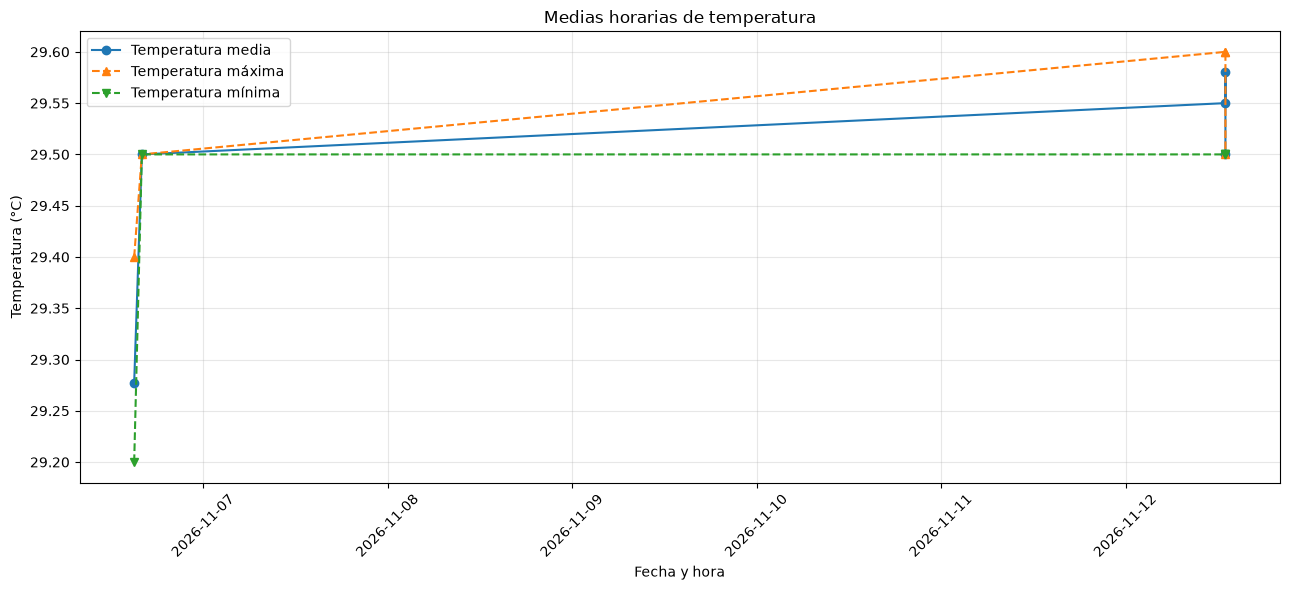

In [12]:
plt.figure(figsize=(13, 6))

plt.plot(
    df_horario["fecha_local"],
    df_horario["temperatura_media"],
    marker="o",
    label="Temperatura media"
)

plt.plot(
    df_horario["fecha_local"],
    df_horario["temperatura_maxima"],
    marker="^",
    linestyle="--",
    label="Temperatura máxima"
)

plt.plot(
    df_horario["fecha_local"],
    df_horario["temperatura_minima"],
    marker="v",
    linestyle="--",
    label="Temperatura mínima"
)

plt.title("Medias horarias de temperatura")
plt.xlabel("Fecha y hora")
plt.ylabel("Temperatura (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:

import os
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from dotenv import load_dotenv
from pymongo import MongoClient

# 1. Conectar con MongoDB
RUTA_PROYECTO = Path.cwd().parent
load_dotenv(RUTA_PROYECTO / "atlas-credentials.env")

uri = os.getenv("MONGODB_URI")

if not uri:
    raise ValueError("No se encontró MONGODB_URI")

cliente = MongoClient(uri)
db = cliente["monitoreo_iot"]
coleccion = db["mediciones_dht22"]

cliente.admin.command("ping")

# 2. Obtener los registros
documentos = list(coleccion.find({}, {"_id": 0}))
df = pd.DataFrame(documentos)

# 3. Conservar únicamente mediciones válidas
df["fecha_hora_recepcion_pc"] = pd.to_datetime(
    df["fecha_hora_recepcion_pc"],
    utc=True
)

df = df[df["estado"] == "OK"].copy()

df = df.dropna(subset=[
    "fecha_hora_recepcion_pc",
    "temperatura_aire_c",
    "humedad_relativa_aire_pct",
    "archivo_origen"
])

# 4. Convertir la fecha a hora local de Perú
df["fecha_local"] = (
    df["fecha_hora_recepcion_pc"]
    .dt.tz_convert("America/Lima")
)

# 5. Ordenar y conservar las sesiones
df = df.sort_values(
    ["archivo_origen", "fecha_local"]
).reset_index(drop=True)

# 6. Crear una tabla resumen por archivo/sesión
resumen_sesiones = (
    df.groupby("archivo_origen")
    .agg(
        cantidad_mediciones=("temperatura_aire_c", "count"),
        temperatura_media=("temperatura_aire_c", "mean"),
        temperatura_minima=("temperatura_aire_c", "min"),
        temperatura_maxima=("temperatura_aire_c", "max"),
        humedad_media=("humedad_relativa_aire_pct", "mean"),
        humedad_minima=("humedad_relativa_aire_pct", "min"),
        humedad_maxima=("humedad_relativa_aire_pct", "max"),
        inicio=("fecha_local", "min"),
        fin=("fecha_local", "max")
    )
    .reset_index()
)

resumen_sesiones


,archivo_origen,cantidad_mediciones,temperatura_media,temperatura_minima,temperatura_maxima,humedad_media,humedad_minima,humedad_maxima,inicio,fin
0,verificacion_dht22_20261106_151438_945598.csv,66,29.277273,29.2,29.4,64.740909,63.8,65.5,2026-11-06 15:14:41.163-05:00,2026-11-06 15:25:33.135-05:00
1,verificacion_dht22_20261106_163529_920518.csv,2,29.500000,29.5,29.5,66.950000,66.8,67.1,2026-11-06 16:35:32.138-05:00,2026-11-06 16:35:42.169-05:00
2,verificacion_dht22_20261112_130717_137823.csv,2,29.550000,29.5,29.6,70.950000,70.8,71.1,2026-11-12 13:07:19.349-05:00,2026-11-12 13:07:29.380-05:00
3,verificacion_dht22_20261112_130743_386281.csv,5,29.580000,29.5,29.6,73.360000,72.1,74.3,2026-11-12 13:07:45.597-05:00,2026-11-12 13:08:25.717-05:00
4,verificacion_dht22_20261112_134309_032510.csv,3,29.500000,29.5,29.5,70.166667,69.8,70.4,2026-11-12 13:43:11.243-05:00,2026-11-12 13:43:31.306-05:00


In [14]:

print("Total de mediciones válidas:", len(df))
print("Cantidad de sesiones:", df["archivo_origen"].nunique())

print("\nColumnas disponibles:")
print(df.columns.tolist())

print("\nPrimeros registros:")
display(df.head())


Total de mediciones válidas: 78
Cantidad de sesiones: 5

Columnas disponibles:
['fila_origen', 'archivo_origen', 'estado', 'fase', 'fecha_hora_recepcion_pc', 'humedad_relativa_aire_pct', 'segundos_desde_inicio', 'temperatura_aire_c', 'fecha_local']

Primeros registros:


,fila_origen,archivo_origen,estado,fase,fecha_hora_recepcion_pc,humedad_relativa_aire_pct,segundos_desde_inicio,temperatura_aire_c,fecha_local
0,1,verificacion_dht22_20261106_151438_945598.csv,OK,VERIFICACION_DHT22,2026-11-06 20:14:41.163+00:00,64.5,2.219,29.3,2026-11-06 15:14:41.163-05:00
1,2,verificacion_dht22_20261106_151438_945598.csv,OK,VERIFICACION_DHT22,2026-11-06 20:14:51.193+00:00,64.7,12.249,29.3,2026-11-06 15:14:51.193-05:00
2,3,verificacion_dht22_20261106_151438_945598.csv,OK,VERIFICACION_DHT22,2026-11-06 20:15:01.224+00:00,64.6,22.280,29.3,2026-11-06 15:15:01.224-05:00
3,4,verificacion_dht22_20261106_151438_945598.csv,OK,VERIFICACION_DHT22,2026-11-06 20:15:11.253+00:00,64.7,32.309,29.2,2026-11-06 15:15:11.253-05:00
4,5,verificacion_dht22_20261106_151438_945598.csv,OK,VERIFICACION_DHT22,2026-11-06 20:15:21.285+00:00,64.4,42.341,29.3,2026-11-06 15:15:21.285-05:00


In [18]:

etiquetas_registros = {}

for i, archivo in enumerate(sesiones, start=1):
    datos = df[df["archivo_origen"] == archivo]

    inicio = datos["fecha_local"].min()

    etiquetas_registros[archivo] = (
        f"Registro {i} - {inicio.strftime('%d/%m/%Y %H:%M')}"
    )

etiquetas_registros


{'verificacion_dht22_20261106_151438_945598.csv': 'Registro 1 - 06/11/2026 15:14',
 'verificacion_dht22_20261106_163529_920518.csv': 'Registro 2 - 06/11/2026 16:35',
 'verificacion_dht22_20261112_130717_137823.csv': 'Registro 3 - 12/11/2026 13:07',
 'verificacion_dht22_20261112_130743_386281.csv': 'Registro 4 - 12/11/2026 13:07',
 'verificacion_dht22_20261112_134309_032510.csv': 'Registro 5 - 12/11/2026 13:43'}

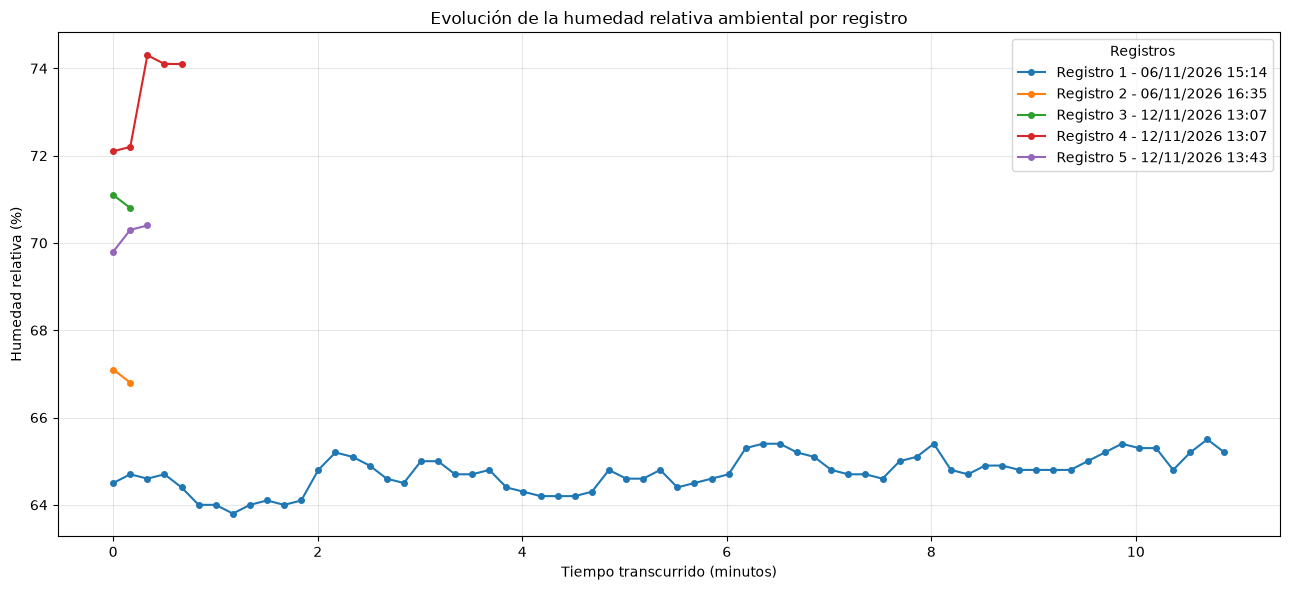

In [19]:

plt.figure(figsize=(13, 6))

for archivo in sesiones:
    datos = df[df["archivo_origen"] == archivo].copy()

    tiempo = (
        datos["fecha_local"] - datos["fecha_local"].min()
    ).dt.total_seconds() / 60

    plt.plot(
        tiempo,
        datos["humedad_relativa_aire_pct"],
        marker="o",
        markersize=4,
        linewidth=1.5,
        label=etiquetas_registros[archivo]
    )

plt.title("Evolución de la humedad relativa ambiental por registro")
plt.xlabel("Tiempo transcurrido (minutos)")
plt.ylabel("Humedad relativa (%)")
plt.grid(alpha=0.3)
plt.legend(title="Registros")
plt.tight_layout()
plt.show()


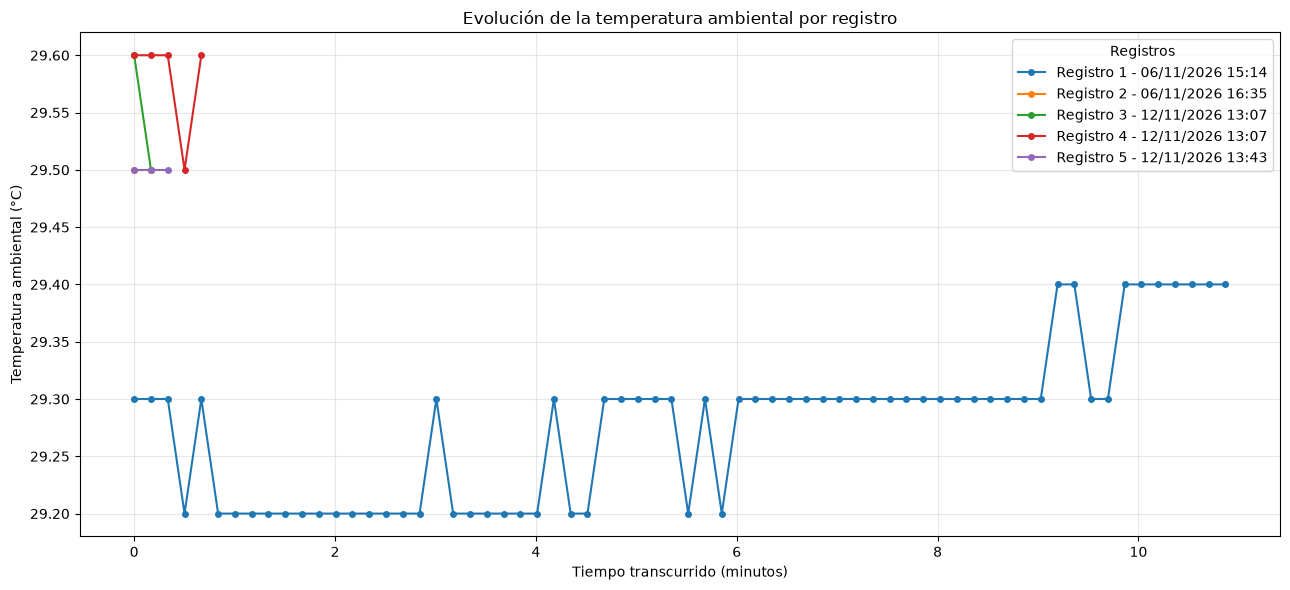

In [20]:

plt.figure(figsize=(13, 6))

for archivo in sesiones:
    datos = df[df["archivo_origen"] == archivo].copy()

    tiempo = (
        datos["fecha_local"] - datos["fecha_local"].min()
    ).dt.total_seconds() / 60

    plt.plot(
        tiempo,
        datos["temperatura_aire_c"],
        marker="o",
        markersize=4,
        linewidth=1.5,
        label=etiquetas_registros[archivo]
    )

plt.title("Evolución de la temperatura ambiental por registro")
plt.xlabel("Tiempo transcurrido (minutos)")
plt.ylabel("Temperatura ambiental (°C)")
plt.grid(alpha=0.3)
plt.legend(title="Registros")
plt.tight_layout()
plt.show()
